<a href="https://colab.research.google.com/github/jason-zermani/A04-clustering/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

In [ ]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

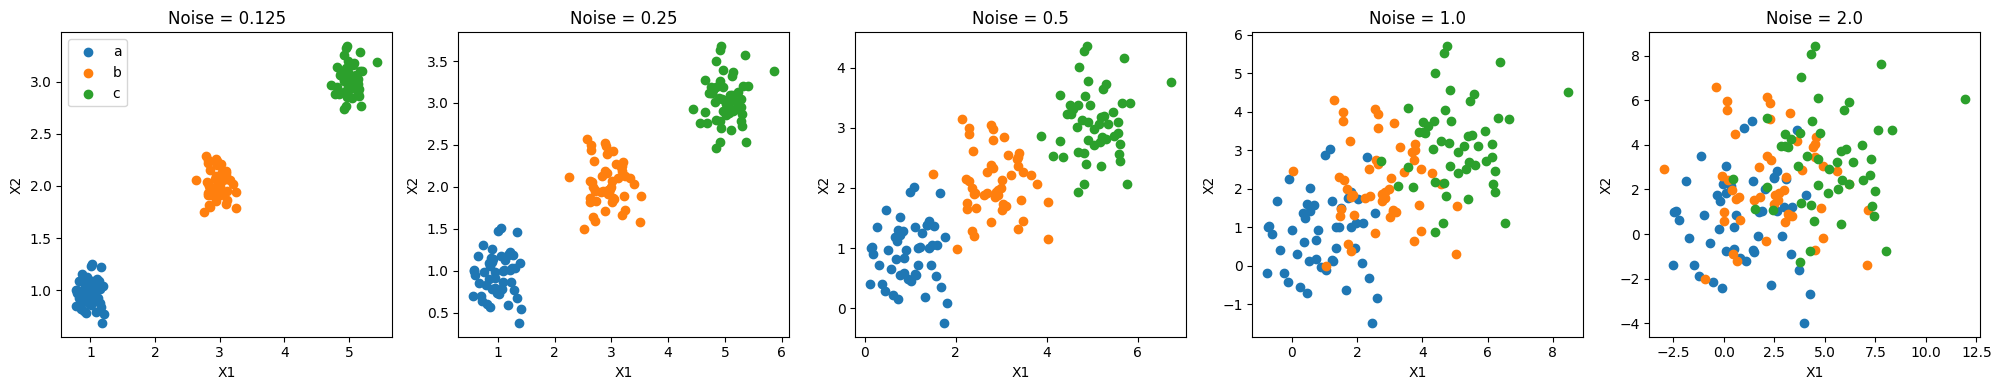

In [ ]:
import matplotlib.pyplot as plt

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    for group in ["a", "b", "c"]:
        data = datasets[i][datasets[i]["group"] == group]
        axes[i].scatter(data["x1"], data["x2"], label=group)

    axes[i].set_title("Noise = " + str(noise_levels[i]))
    axes[i].set_xlabel("X1")
    axes[i].set_ylabel("X2")

axes[0].legend()
plt.tight_layout()
plt.show()

As noise goes from 0.125 to 2.0,  clusters become more spread out and overlap more

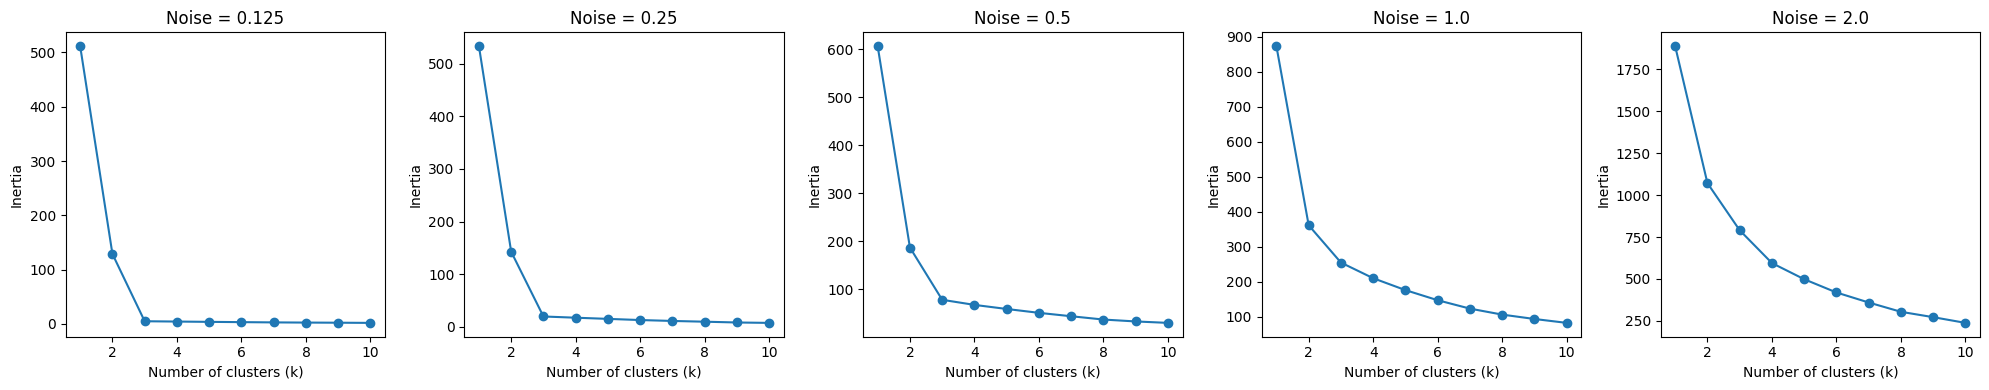

In [ ]:
from sklearn.cluster import KMeans

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    X = datasets[i][["x1", "x2"]]
    inertia = []

    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=100, n_init=10)
        model.fit(X)
        inertia.append(model.inertia_)

    axes[i].plot(range(1, 11), inertia, marker="o")
    axes[i].set_title("Noise = " + str(noise_levels[i]))
    axes[i].set_xlabel("Number of clusters (k)")
    axes[i].set_ylabel("Inertia")

plt.tight_layout()
plt.show()

As noise increases the elbow in the plot becomes less clear. Low noise = elbow is easier to identify around k=3. High noise = smoother curve making it harder to choose k

The elbow shows where adding more clusters stops making a big difference. Since the data has three groups k=3 makes the most sense. When noise is low, the elbow is easier to see. As noise increases the groups overlap more, making it harder to tell how many clusters there should be.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

In [ ]:
import pandas as pd

df = pd.read_csv("./sample_data/SIPRI Military Expenditure Database.csv")

df = df[df["Year"] == 2020]
df = df.dropna()

print(df.shape)
print(df.dtypes)
print(df.head())

(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
     index  Year      Country  Spending (2020 USD)  Percent of GDP  \
32      32  2020  Afghanistan           279.576955        0.013589   
66      66  2020      Albania           187.433234        0.012583   
100    100  2020      Algeria          9708.277440        0.066600   
134    134  2020       Angola           993.594405        0.014442   
168    168  2020    Argentina          2830.929705        0.007269   

     Percent of Government Spending  Spending per Capita  
32                         0.049728             7.181899  
66                         0.037952            65.126211  
100                        0.173924           221.392384  
134                       

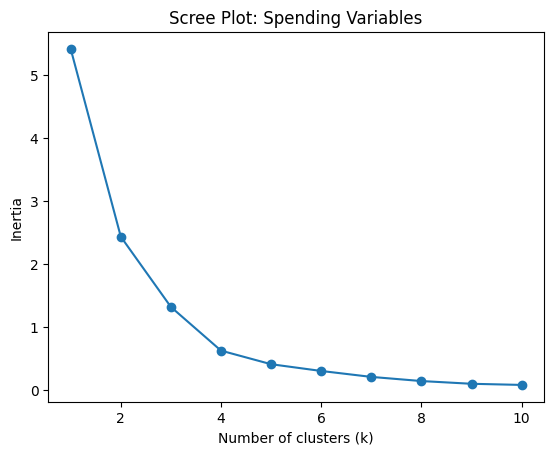

In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

cols1 = ["Spending (2020 USD)", "Spending per Capita"]

X1 = df[cols1].copy()
X1 = MinMaxScaler().fit_transform(X1)

inertia1 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X1)
    inertia1.append(model.inertia_)

plt.plot(range(1, 11), inertia1, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: Spending Variables")
plt.show()

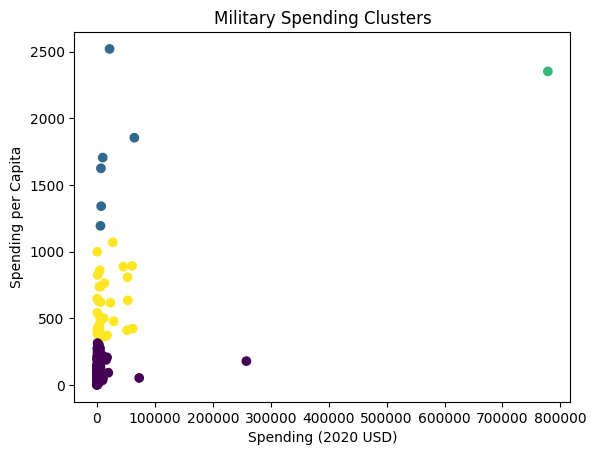

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                      111.0    4859.185065  25405.739131       8.622460   
1                        6.0   19443.362047  22861.507114    6095.708713   
2                        1.0  778397.200000           NaN  778397.200000   
3                       30.0   17077.591354  20583.053357     405.790494   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0            130.010211     382.464677    2297.032353  257973.429834   
1           7023.251766    8624.225729   18857.070183   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   
3           2294.039665    5857.060

In [ ]:
k1 = 4

model1 = KMeans(n_clusters=k1, random_state=42, n_init=10)
df["cluster1"] = model1.fit_predict(X1)

plt.scatter(df[cols1[0]], df[cols1[1]], c=df["cluster1"])
plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.title("Military Spending Clusters")
plt.show()

print(df.groupby("cluster1")[cols1].describe())
print(df.loc[df["Country"] == "United States", ["Country", "cluster1"]])

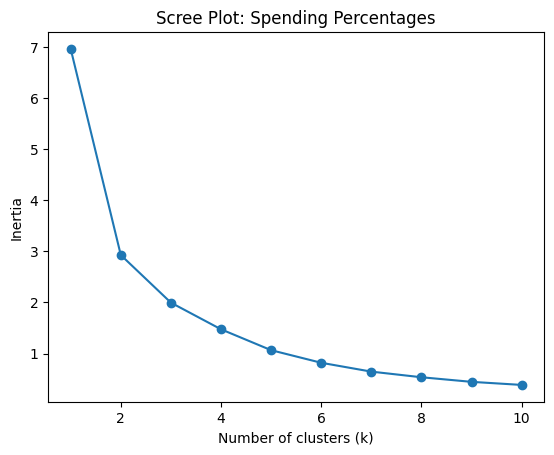

In [ ]:
cols2 = ["Percent of Government Spending", "Percent of GDP"]

X2 = MinMaxScaler().fit_transform(df[cols2])

inertia2 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X2)
    inertia2.append(model.inertia_)

plt.plot(range(1, 11), inertia2, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: Spending Percentages")
plt.show()

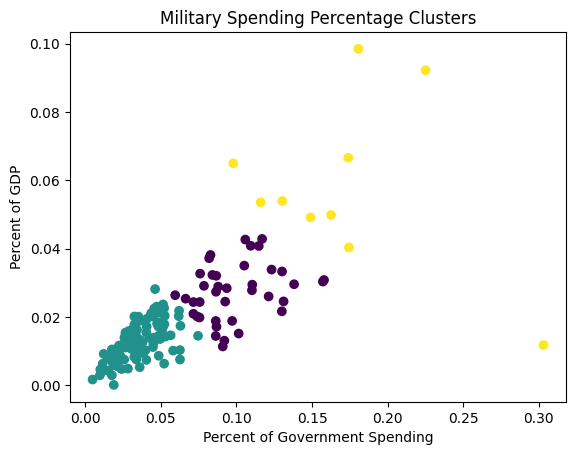

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       mi

In [ ]:
k2 = 3

model2 = KMeans(n_clusters=k2, random_state=42, n_init=10)
df["cluster2"] = model2.fit_predict(X2)

plt.scatter(df[cols2[0]], df[cols2[1]], c=df["cluster2"])
plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.title("Military Spending Percentage Clusters")
plt.show()

print(df.groupby("cluster2")[cols2].describe())

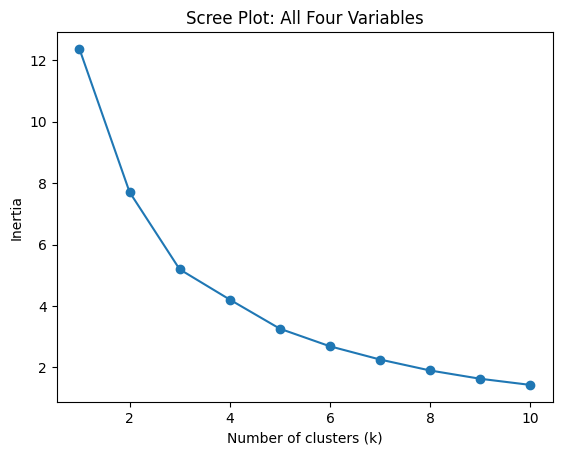

In [ ]:
cols3 = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]

X3 = MinMaxScaler().fit_transform(df[cols3])

inertia3 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X3)
    inertia3.append(model.inertia_)

plt.plot(range(1, 11), inertia3, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: All Four Variables")
plt.show()

In [ ]:
k3 = 3

model3 = KMeans(n_clusters=k3, random_state=42, n_init=10)
df["cluster3"] = model3.fit_predict(X3)

print(df.groupby("cluster3")[cols3].mean())
print(df.loc[df["Country"] == "United States", ["Country", "cluster3"]])

          Spending (2020 USD)  Spending per Capita  \
cluster3                                             
0                 8786.086602           212.689100   
1               147964.582042          1875.150751   
2                 7086.472777           196.926833   

          Percent of Government Spending  Percent of GDP  
cluster3                                                  
0                               0.122985        0.033492  
1                               0.135351        0.062634  
2                               0.040350        0.013419  
Empty DataFrame
Columns: [Country, cluster3]
Index: []


Yes there were some useful patterns. Some countries had higher total spending,  others spent more per person or a larger percentage of their GDP. Using all four variables gave a more complete picture of military spending. The results depended on the number of clusters chosen.

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])

    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])

    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        "x1": X1[0, :],
        "x2": X1[1, :],
        "group": "a"
    })

    gdf2 = pd.DataFrame({
        "x1": X2[0, :],
        "x2": X2[1, :],
        "group": "b"
    })

    gdf3 = pd.DataFrame({
        "x1": X3[0, :],
        "x2": X3[1, :],
        "group": "c"
    })

    df = pd.concat([gdf1, gdf2, gdf3], axis=0)

    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]

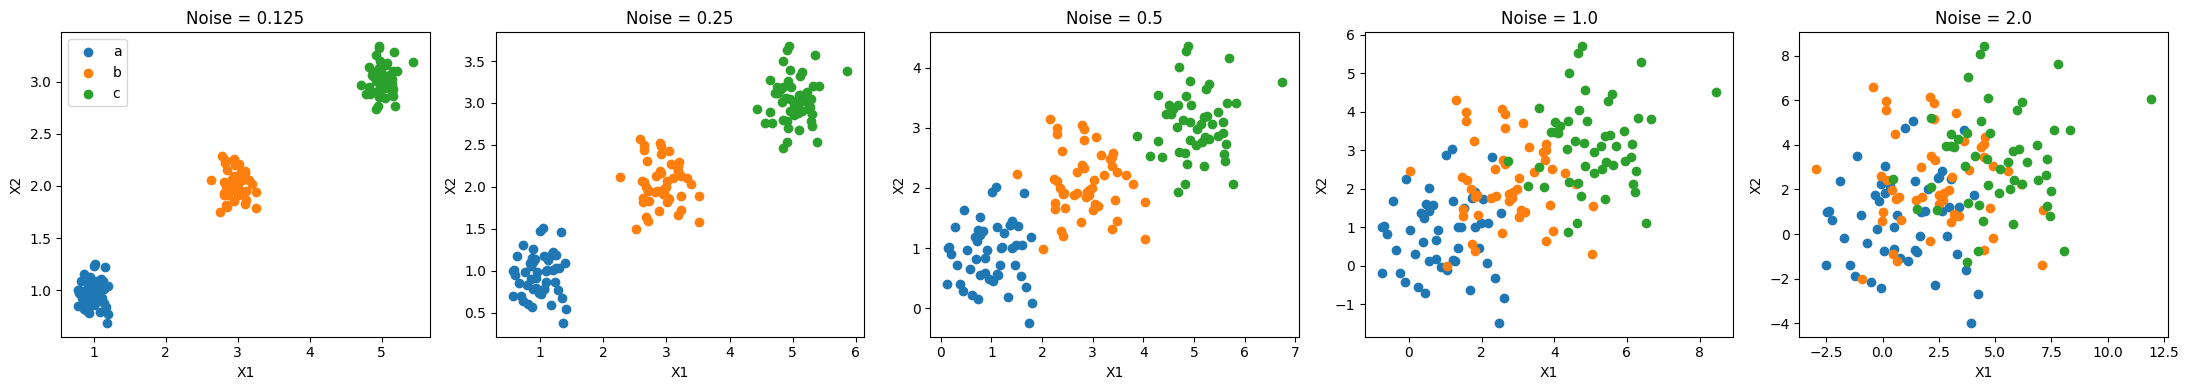

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for i in range(5):
    for group in ["a", "b", "c"]:
        data = datasets[i][datasets[i]["group"] == group]

        axes[i].scatter(
            data["x1"],
            data["x2"],
            label=group
        )

    axes[i].set_title("Noise = " + str(noise_levels[i]))
    axes[i].set_xlabel("X1")
    axes[i].set_ylabel("X2")

axes[0].legend()
plt.tight_layout()
plt.show()

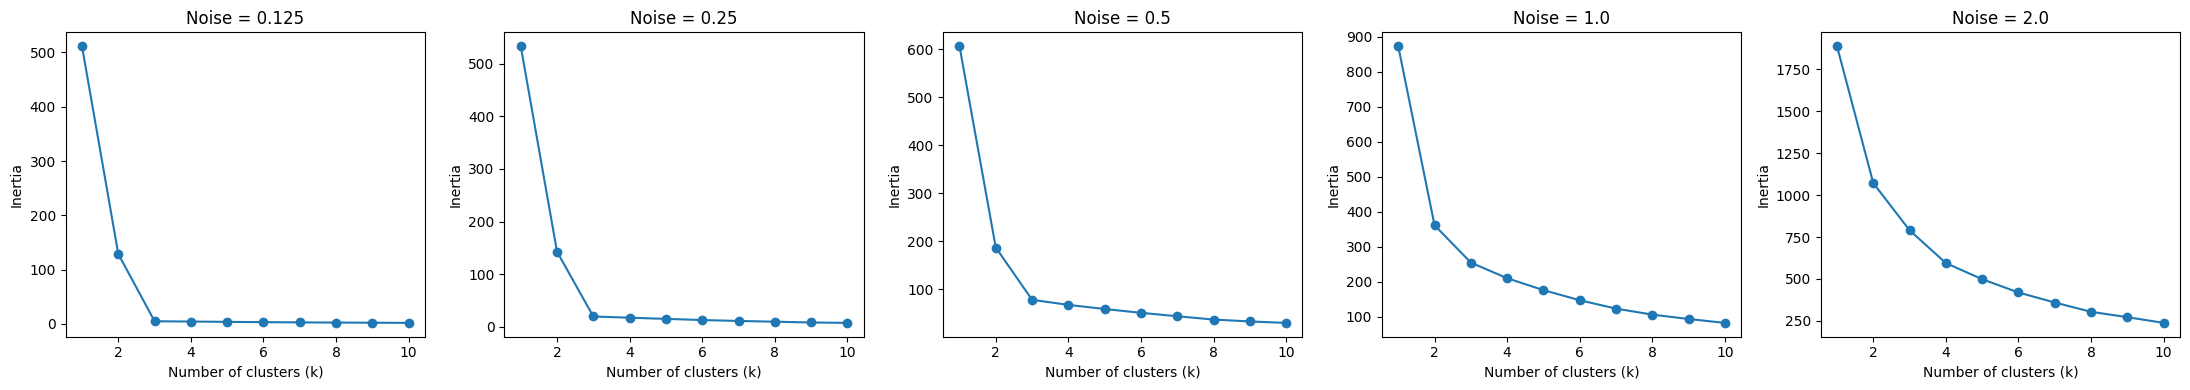

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for i in range(5):
    X = datasets[i][["x1", "x2"]]

    inertia = []

    for k in range(1, 11):
        model = KMeans(
            n_clusters=k,
            random_state=100,
            n_init=10
        )

        model.fit(X)
        inertia.append(model.inertia_)

    axes[i].plot(range(1, 11), inertia, marker="o")
    axes[i].set_title("Noise = " + str(noise_levels[i]))
    axes[i].set_xlabel("Number of clusters (k)")
    axes[i].set_ylabel("Inertia")

plt.tight_layout()
plt.show()

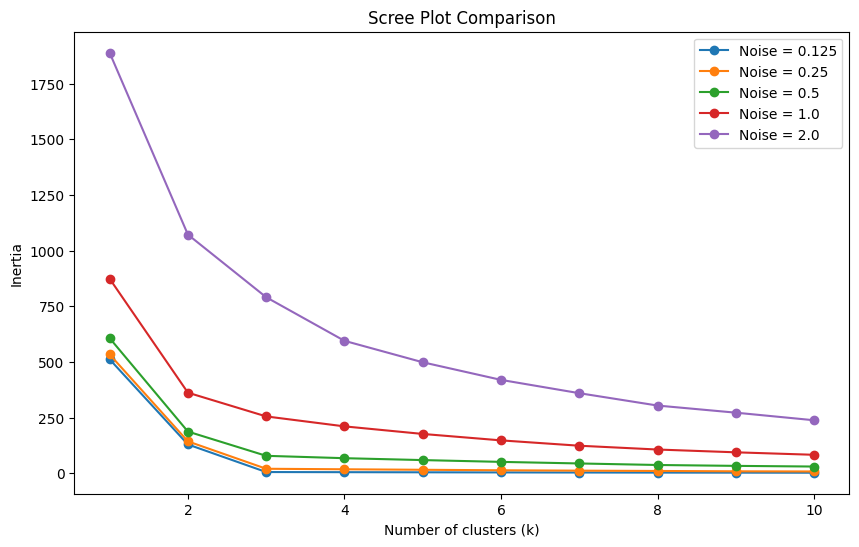

In [ ]:
plt.figure(figsize=(10, 6))

for i in range(5):
    X = datasets[i][["x1", "x2"]]

    inertia = []

    for k in range(1, 11):
        model = KMeans(
            n_clusters=k,
            random_state=100,
            n_init=10
        )

        model.fit(X)
        inertia.append(model.inertia_)

    plt.plot(
        range(1, 11),
        inertia,
        marker="o",
        label="Noise = " + str(noise_levels[i])
    )

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot Comparison")
plt.legend()
plt.show()


The elbow helps show when splitting the data into additional groups stops being very helpful. Since the dataset contains three original groups, using three clusters is a reasonable starting point. When there is less noise, the groups are easier to separate and the best value of
k
k is more obvious. With more noise, the groups mix together, so choosing the right number of clusters becomes more difficult.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

df = pd.read_csv("/content/sample_data/SIPRI Military Expenditure Database.csv")

print(df.columns)
print(df.head())

Index(['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP',
       'Percent of Government Spending', 'Spending per Capita'],
      dtype='object')
   index  Year      Country  Spending (2020 USD)  Percent of GDP  \
0      0  1988  Afghanistan                  NaN             NaN   
1      1  1989  Afghanistan                  NaN             NaN   
2      2  1990  Afghanistan                  NaN             NaN   
3      3  1991  Afghanistan                  NaN             NaN   
4      4  1992  Afghanistan                  NaN             NaN   

   Percent of Government Spending  Spending per Capita  
0                             NaN                  NaN  
1                             NaN                  NaN  
2                             NaN                  NaN  
3                             NaN                  NaN  
4                             NaN                  NaN  


In [ ]:
df = df[df["Year"] == 2020].copy()
df = df.dropna()

print("Number of countries:", len(df))
print(df.dtypes)
print(df.head())

Number of countries: 148
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
     index  Year      Country  Spending (2020 USD)  Percent of GDP  \
32      32  2020  Afghanistan           279.576955        0.013589   
66      66  2020      Albania           187.433234        0.012583   
100    100  2020      Algeria          9708.277440        0.066600   
134    134  2020       Angola           993.594405        0.014442   
168    168  2020    Argentina          2830.929705        0.007269   

     Percent of Government Spending  Spending per Capita  
32                         0.049728             7.181899  
66                         0.037952            65.126211  
100                        0.173924           221.392384  
134       

In [ ]:
cols = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

print(df[cols].dtypes)
print(df[cols].isnull().sum())
print(df[cols].describe())

Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
Spending (2020 USD)               0
Spending per Capita               0
Percent of Government Spending    0
Percent of GDP                    0
dtype: int64
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.04

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print(df.select_dtypes(include="object").head())

Duplicate rows: 0
         Country
32   Afghanistan
66       Albania
100      Algeria
134       Angola
168    Argentina


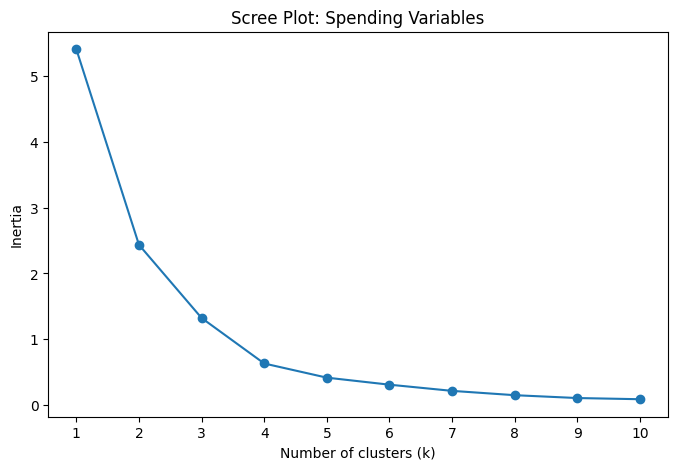

In [ ]:
cols1 = ["Spending (2020 USD)", "Spending per Capita"]

X1 = MinMaxScaler().fit_transform(df[cols1])

inertia1 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X1)
    inertia1.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia1, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: Spending Variables")
plt.xticks(range(1, 11))
plt.show()

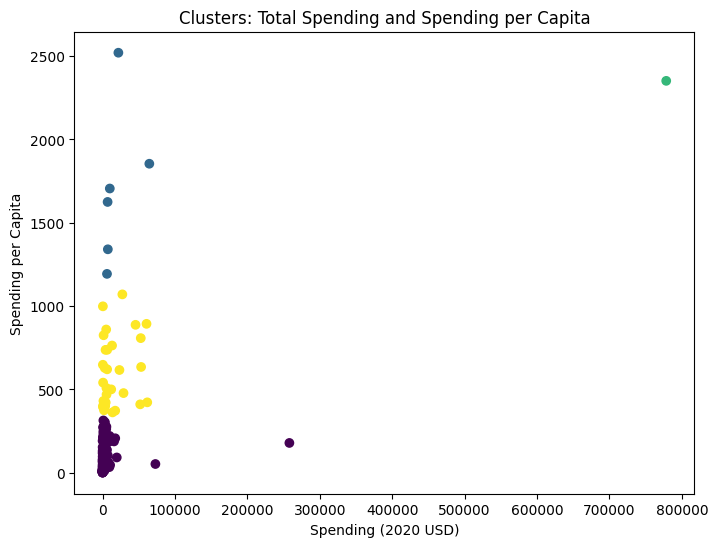

In [ ]:
k1 = 4

model1 = KMeans(n_clusters=k1, random_state=42, n_init=10)
df["cluster1"] = model1.fit_predict(X1)

plt.figure(figsize=(8, 6))
plt.scatter(
    df["Spending (2020 USD)"],
    df["Spending per Capita"],
    c=df["cluster1"],
    cmap="viridis"
)

plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.title("Clusters: Total Spending and Spending per Capita")
plt.show()

In [ ]:
print(df.groupby("cluster1")[cols1].describe())

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                      111.0    4859.185065  25405.739131       8.622460   
1                        6.0   19443.362047  22861.507114    6095.708713   
2                        1.0  778397.200000           NaN  778397.200000   
3                       30.0   17077.591354  20583.053357     405.790494   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0            130.010211     382.464677    2297.032353  257973.429834   
1           7023.251766    8624.225729   18857.070183   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   
3           2294.039665    5857.060

In [ ]:
print(df.groupby("cluster1")[cols1].mean().round(2))
print(df["cluster1"].value_counts().sort_index())

          Spending (2020 USD)  Spending per Capita
cluster1                                          
0                     4859.19                80.06
1                    19443.36              1706.72
2                   778397.20              2351.63
3                    17077.59               607.48
cluster1
0    111
1      6
2      1
3     30
Name: count, dtype: int64


In [ ]:
print(df[df["Country"].str.contains(
    "United States", case=False, na=False
)][["Country"] + cols1 + ["cluster1"]])

                       Country  Spending (2020 USD)  Spending per Capita  \
5540  United States of America             778397.2          2351.631858   

      cluster1  
5540         2  


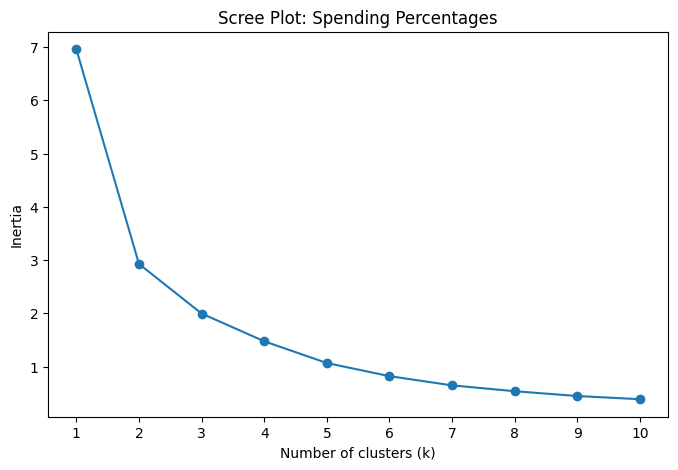

In [ ]:
cols2 = ["Percent of Government Spending", "Percent of GDP"]

X2 = MinMaxScaler().fit_transform(df[cols2])

inertia2 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X2)
    inertia2.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia2, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: Spending Percentages")
plt.xticks(range(1, 11))
plt.show()

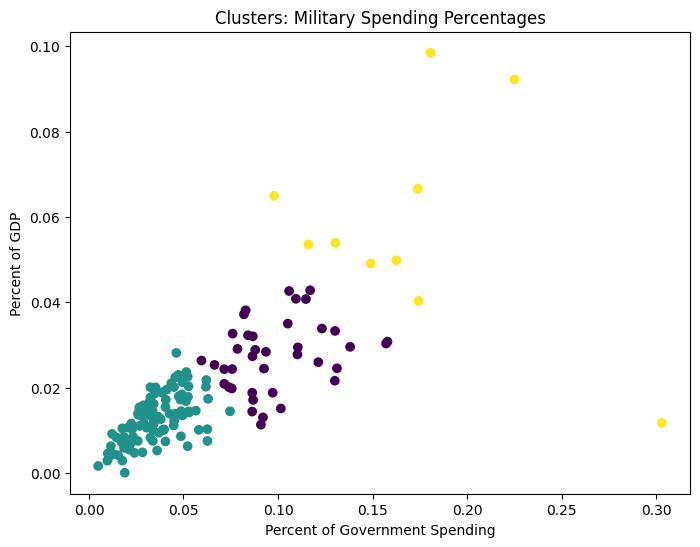

In [ ]:
k2 = 3

model2 = KMeans(n_clusters=k2, random_state=42, n_init=10)
df["cluster2"] = model2.fit_predict(X2)

plt.figure(figsize=(8, 6))
plt.scatter(
    df["Percent of Government Spending"],
    df["Percent of GDP"],
    c=df["cluster2"],
    cmap="viridis"
)

plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.title("Clusters: Military Spending Percentages")
plt.show()

In [ ]:
print(df.groupby("cluster2")[cols2].describe())
print(df.groupby("cluster2")[cols2].mean().round(2))
print(df["cluster2"].value_counts().sort_index())

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       mi

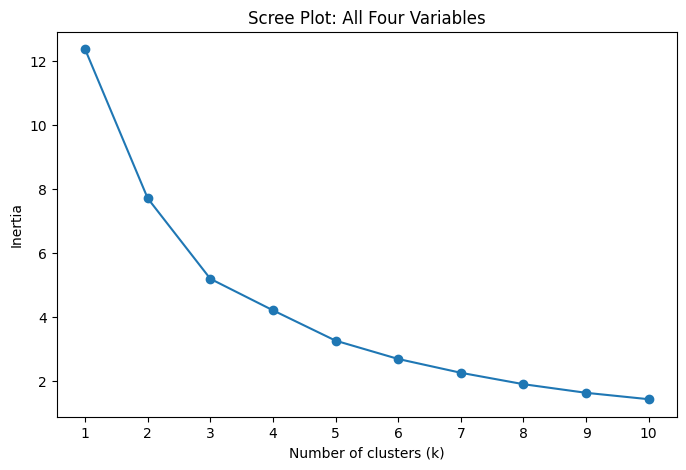

In [ ]:
cols3 = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

X3 = MinMaxScaler().fit_transform(df[cols3])

inertia3 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X3)
    inertia3.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia3, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: All Four Variables")
plt.xticks(range(1, 11))
plt.show()

In [ ]:
k3 = 3

model3 = KMeans(n_clusters=k3, random_state=42, n_init=10)
df["cluster3"] = model3.fit_predict(X3)

print(df.groupby("cluster3")[cols3].describe())
print(df.groupby("cluster3")[cols3].mean().round(2))
print(df["cluster3"].value_counts().sort_index())

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster3                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                      111.0    7086.472777   26479.379918     8.622460   

                                                                  \
                  25%           50%           75%            max   
cluster3                                                           
0          467.787851   1404.787234   7739.166193   72937.064048   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          130.010211    567.650747   3910.107493  257973.429834   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...             

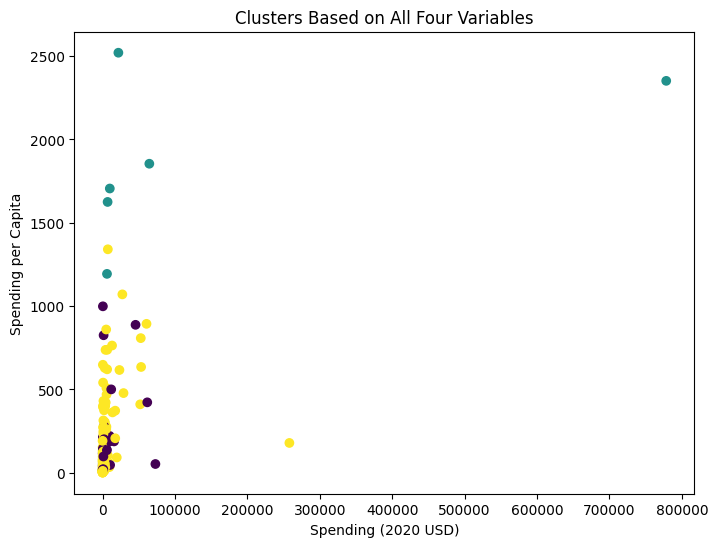

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df["Spending (2020 USD)"],
    df["Spending per Capita"],
    c=df["cluster3"],
    cmap="viridis"
)

plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.title("Clusters Based on All Four Variables")
plt.show()

Yes, k-means clustering was useful for identifying differences in military spending across countries. By grouping countries with similar spending characteristics, the algorithm made it easier to compare their military budgets and understand how their spending patterns differed.

The first analysis focused on total military spending and spending per capita, helping distinguish countries that spend large amounts overall from those that spend more relative to their populations. The second analysis focused on military spending as a percentage of government spending and GDP, showing how heavily countries prioritize military expenditure relative to their available resources. Using all four variables combined these perspectives and allowed the model to consider more aspects of military spending at once.

However, k-means has limitations. The clusters depend on the number of clusters selected, and different choices can produce different groupings. The algorithm also identifies similarities in the data but does not explain why countries have those spending patterns. Factors such as population, economic conditions, security threats, and political decisions could help explain the differences.

Overall, I found k-means useful as an exploratory tool for organizing countries into groups with similar military spending patterns. The results provide a starting point for comparing countries, but they should not be treated as definitive categories or as explanations for why countries spend what they do.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI helped me verify all of the code with an in depth analysis of everything. It also helped me understand everything I was doing with an explanation of all of the code and different plots. For example it explained how to use and verify the k values for all of the chats. Overall, I have said this for every assignment, but the AI made all of my solutions more in depth and proper. I always have the right concepts but the AI always goes through my answers and makes them more in depth and robust.